# 부두별 선석별 평균선석점유율
- 선석 점유율 = Σ 작업시간 ÷ (선석 수 × 기간 시간) × 100
- 작업시간 = 접안-출항

## 자료없음
- 2부두 9선석:2022~2025년 접안, 출항 기록 없음
- 4부두 4선석:4선석의 접안, 출항 기록 없음

# 부두별 선석별 총작업시간

4부두: 오류·누락 1건 제외

2022~2025년 부두별·선석별 총 작업시간
 부두  선석  기록수  총작업시간_시간
  1   1 1110  25490.57
  1   2  975  27742.68
  1   3  843  29446.03
  2   4 1710  29982.72
  2   5 1536  30264.97
  2   6 1303  30925.38
  2   7 1136  31080.73
  2   8 1041  31347.87
  2   9    0     자료 없음
  3   1 1244  29537.48
  3   2 1332  21962.97
  3   3  740  21834.08
  3   4  456   8761.45
  4   1 1069  20503.68
  4   2 1135  26613.38
  4   3 1215  27478.12
  4   4    0     자료 없음
  5   1 1362  29422.40
  5   2 1074  27962.50
  5   3  372   7677.90
  5   4 1064  26947.87


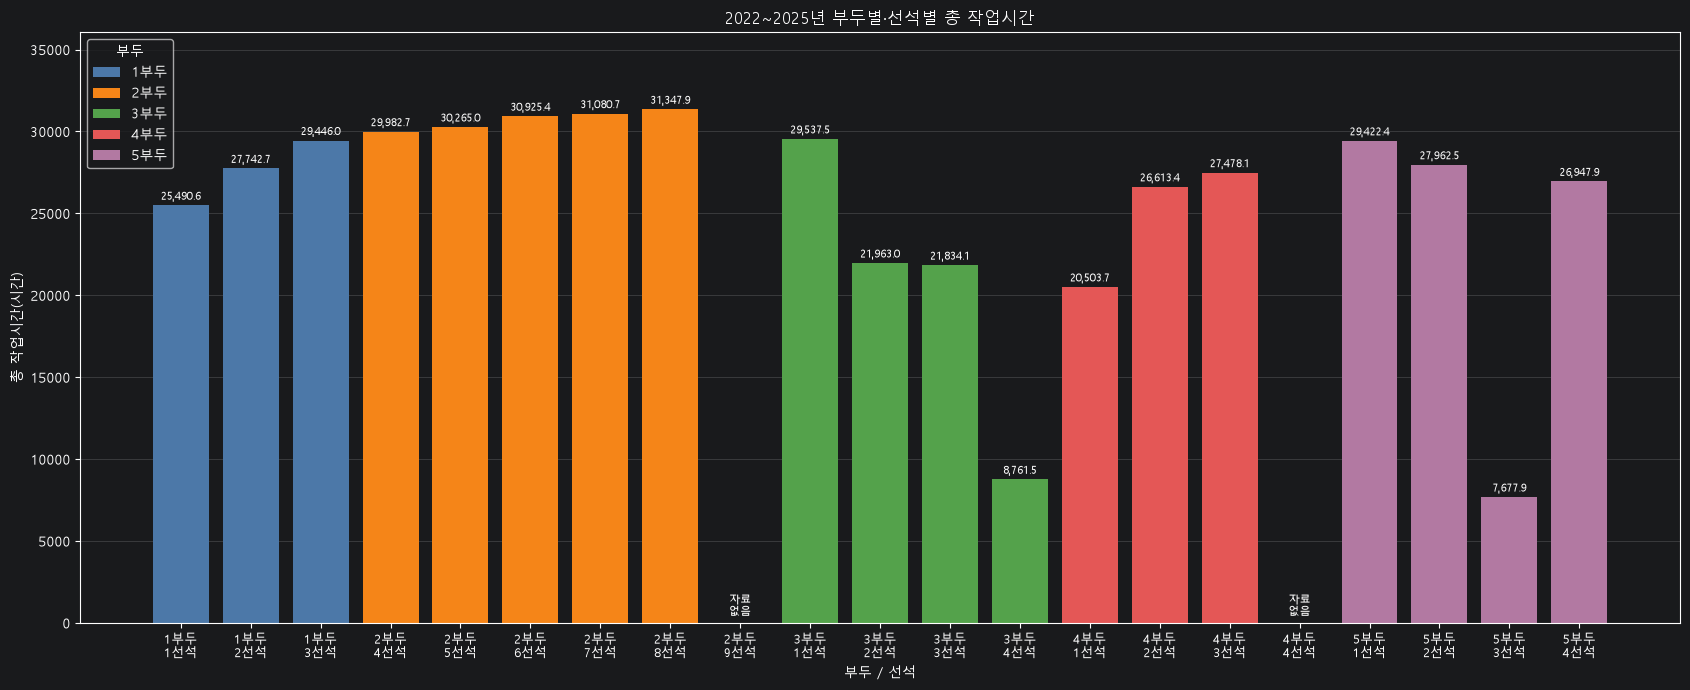

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. 한글 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. CSV 불러오기
DATA_DIR = r"C:\work\Final_Project\data"

port1 = pd.read_csv(DATA_DIR + "/port1.csv", encoding="utf-8-sig")
port2 = pd.read_csv(DATA_DIR + "/port2.csv", encoding="cp949")
port3 = pd.read_csv(DATA_DIR + "/port3.csv", encoding="cp949")
port4 = pd.read_csv(DATA_DIR + "/port4.csv", encoding="cp949")
port5 = pd.read_csv(DATA_DIR + "/port5.csv", encoding="cp949")

ports = [
    (1, port1),
    (2, port2),
    (3, port3),
    (4, port4),
    (5, port5),
]

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")

# 사진의 선석수와 CSV의 선석 번호 기준
expected_berths = {
    1: [1, 2, 3],
    2: [4, 5, 6, 7, 8, 9],
    3: [1, 2, 3, 4],
    4: [1, 2, 3, 4],
    5: [1, 2, 3, 4],
}

# 3. 작업시간 계산
frames = []

for number, port in ports:
    data = port.copy()

    data["접안시각"] = pd.to_datetime(
        data["접안(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    data["출항시각"] = pd.to_datetime(
        data["출항(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    # 시각·선석 누락 또는 출항이 접안보다 빠른 기록 제외
    invalid = (
        data[["접안시각", "출항시각", "선석"]].isna().any(axis=1)
        | (data["출항시각"] < data["접안시각"])
    )

    if invalid.any():
        print(f"{number}부두: 오류·누락 {invalid.sum()}건 제외")

    data = data.loc[~invalid].copy()

    # 분석 기간과 겹치는 기록 선택
    data = data.loc[
        (data["접안시각"] < END)
        & (data["출항시각"] > START)
    ].copy()

    # 2022~2025년에 포함되는 구간만 반영
    work_start = data["접안시각"].clip(lower=START)
    work_end = data["출항시각"].clip(upper=END)

    # 작업시간 = 출항시각 - 접안시각
    data["작업시간_시간"] = (
        work_end - work_start
    ).dt.total_seconds() / 3600

    data["부두"] = number

    frames.append(
        data[["부두", "선석", "작업시간_시간"]]
    )

detail = pd.concat(frames, ignore_index=True)

# 4. 부두별·선석별 총 작업시간
result = (
    detail.groupby(["부두", "선석"])
    .agg(
        기록수=("작업시간_시간", "count"),
        총작업시간_시간=("작업시간_시간", "sum"),
    )
)

# 기록이 없는 선석도 표시하되, 0시간으로 단정하지 않음
expected_index = pd.MultiIndex.from_tuples(
    [
        (number, berth)
        for number, berths in expected_berths.items()
        for berth in berths
    ],
    names=["부두", "선석"],
)

result = result.reindex(expected_index).reset_index()
result["기록수"] = result["기록수"].fillna(0).astype(int)

print("\n2022~2025년 부두별·선석별 총 작업시간")
print(result.round(2).to_string(index=False, na_rep="자료 없음"))

# 5. 바그래프
labels = (
    result["부두"].astype(str) + "부두\n"
    + result["선석"].astype(str) + "선석"
)

port_colors = {
    1: "#4C78A8",
    2: "#F58518",
    3: "#54A24B",
    4: "#E45756",
    5: "#B279A2",
}

fig, ax = plt.subplots(figsize=(17, 7))

bars = ax.bar(
    labels,
    result["총작업시간_시간"],
    color=result["부두"].map(port_colors),
)

maximum = result["총작업시간_시간"].max()
upper = max(maximum * 1.15, 1) if pd.notna(maximum) else 1

for bar, value in zip(bars, result["총작업시간_시간"]):
    if pd.isna(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            upper * 0.01,
            "자료\n없음",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    else:
        ax.annotate(
            f"{value:,.1f}",
            xy=(bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

ax.set_title("2022~2025년 부두별·선석별 총 작업시간")
ax.set_xlabel("부두 / 선석")
ax.set_ylabel("총 작업시간(시간)")
ax.set_ylim(0, upper)

ax.tick_params(axis="x", labelsize=9)
ax.ticklabel_format(axis="y", style="plain", useOffset=False)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.legend(
    handles=[
        Patch(facecolor=color, label=f"{number}부두")
        for number, color in port_colors.items()
    ],
    title="부두",
)

plt.tight_layout()
plt.show()

# 선석수

In [20]:
import pandas as pd

# 앞서 제공한 이미지 기준 선석 수
선석수 = {1: 3, 2: 6, 3: 4, 4: 4, 5: 4}

선석수표 = pd.DataFrame({
    "부두": list(선석수.keys()),
    "선석수": list(선석수.values())
})

print(선석수표.to_string(index=False))

 부두  선석수
  1    3
  2    6
  3    4
  4    4
  5    4


분석 기간: 35,064시간
4부두: 오류·누락 1건 제외

부두별·선석별 선석점유율
 부두  선석  기록수  총작업시간_시간     자료상태  선석점유율_퍼센트
  1   1 1110  25490.57    기록 있음      72.70
  1   2  975  27742.68    기록 있음      79.12
  1   3  843  29446.03    기록 있음      83.98
  2   4 1710  29982.72    기록 있음      85.51
  2   5 1536  30264.97    기록 있음      86.31
  2   6 1303  30925.38    기록 있음      88.20
  2   7 1136  31080.73    기록 있음      88.64
  2   8 1041  31347.87    기록 있음      89.40
  2   9    0     자료 없음 자료 확인 필요      자료 없음
  3   1 1244  29537.48    기록 있음      84.24
  3   2 1332  21962.97    기록 있음      62.64
  3   3  740  21834.08    기록 있음      62.27
  3   4  456   8761.45    기록 있음      24.99
  4   1 1069  20503.68    기록 있음      58.48
  4   2 1135  26613.38    기록 있음      75.90
  4   3 1215  27478.12    기록 있음      78.37
  4   4    0     자료 없음 자료 확인 필요      자료 없음
  5   1 1362  29422.40    기록 있음      83.91
  5   2 1074  27962.50    기록 있음      79.75
  5   3  372   7677.90    기록 있음      21.90
  5   4 1064  26947.87    기록 있음      76.85

부두 전체

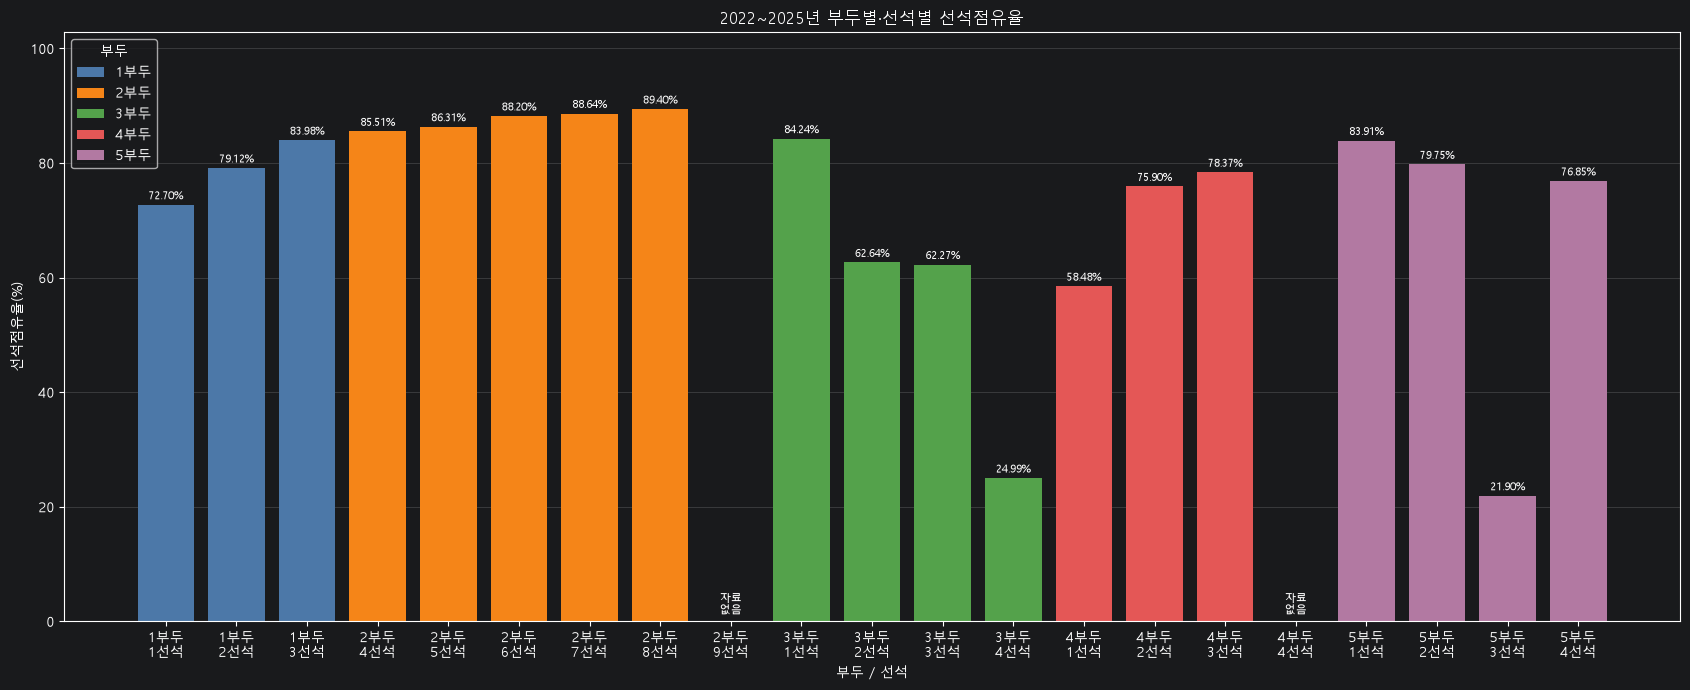

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. 한글 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. 파일 불러오기
DATA_DIR = r"C:\work\Final_Project\data"

port1 = pd.read_csv(DATA_DIR + "/port1.csv", encoding="utf-8-sig")
port2 = pd.read_csv(DATA_DIR + "/port2.csv", encoding="cp949")
port3 = pd.read_csv(DATA_DIR + "/port3.csv", encoding="cp949")
port4 = pd.read_csv(DATA_DIR + "/port4.csv", encoding="cp949")
port5 = pd.read_csv(DATA_DIR + "/port5.csv", encoding="cp949")

ports = [
    (1, port1),
    (2, port2),
    (3, port3),
    (4, port4),
    (5, port5),
]

# 사진 기준 부두별 선석수
berth_counts = {
    1: 3,
    2: 6,
    3: 4,
    4: 4,
    5: 4,
}

# CSV의 선석 번호 기준
# 2부두는 4~9번을 사용
expected_berths = {
    1: [1, 2, 3],
    2: [4, 5, 6, 7, 8, 9],
    3: [1, 2, 3, 4],
    4: [1, 2, 3, 4],
    5: [1, 2, 3, 4],
}

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")

period_hours = (END - START).total_seconds() / 3600
print(f"분석 기간: {period_hours:,.0f}시간")

# 3. 기간 내 작업시간 계산
frames = []

for number, port in ports:
    data = port.copy()

    data["접안시각"] = pd.to_datetime(
        data["접안(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    data["출항시각"] = pd.to_datetime(
        data["출항(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    invalid = (
        data[["접안시각", "출항시각", "선석"]].isna().any(axis=1)
        | (data["출항시각"] < data["접안시각"])
    )

    if invalid.any():
        print(f"{number}부두: 오류·누락 {invalid.sum()}건 제외")

    data = data.loc[~invalid].copy()

    # 분석 기간과 겹치는 기록만 선택
    data = data.loc[
        (data["접안시각"] < END)
        & (data["출항시각"] > START)
    ].copy()

    # 기간 경계를 넘는 시간은 제외
    work_start = data["접안시각"].clip(lower=START)
    work_end = data["출항시각"].clip(upper=END)

    data["작업시간_시간"] = (
        work_end - work_start
    ).dt.total_seconds() / 3600

    data["부두"] = number

    frames.append(
        data[["부두", "선석", "작업시간_시간"]]
    )

detail = pd.concat(frames, ignore_index=True)

# 4. 부두별·선석별 총 작업시간
observed = (
    detail.groupby(["부두", "선석"])
    .agg(
        기록수=("작업시간_시간", "count"),
        총작업시간_시간=("작업시간_시간", "sum"),
    )
)

# 사진 기준 전체 선석을 결과에 포함
expected_index = pd.MultiIndex.from_tuples(
    [
        (number, berth)
        for number, berths in expected_berths.items()
        for berth in berths
    ],
    names=["부두", "선석"],
)

result = observed.reindex(expected_index).reset_index()

# 기록이 없는 선석은 0시간으로 단정하지 않고 결측값 유지
result["기록수"] = result["기록수"].fillna(0).astype(int)
result["자료상태"] = result["기록수"].apply(
    lambda count: "기록 있음" if count > 0 else "자료 확인 필요"
)

# 선석 하나의 분모에는 선석수 1개 적용
result["선석점유율_퍼센트"] = (
    result["총작업시간_시간"] / period_hours * 100
)

print("\n부두별·선석별 선석점유율")
print(result.round(2).to_string(index=False, na_rep="자료 없음"))

# 5. 부두 전체 선석점유율
port_result = (
    result.groupby("부두", as_index=False)
    .agg(
        확인된작업시간_시간=(
            "총작업시간_시간",
            lambda values: values.sum(min_count=1),
        ),
        자료있는선석수=("총작업시간_시간", "count"),
    )
)

port_result["전체선석수"] = port_result["부두"].map(berth_counts)

port_result["부두점유율_퍼센트"] = (
    port_result["확인된작업시간_시간"]
    / (port_result["전체선석수"] * period_hours)
    * 100
)

# 일부 선석 자료가 없으면 부두 전체 점유율은 확정하지 않음
incomplete = (
    port_result["자료있는선석수"]
    < port_result["전체선석수"]
)

port_result.loc[
    incomplete, "부두점유율_퍼센트"
] = float("nan")

print("\n부두 전체 선석점유율")
print(port_result.round(2).to_string(index=False, na_rep="자료 확인 필요"))

# 6. 선석별 점유율 바그래프
labels = (
    result["부두"].astype(str) + "부두\n"
    + result["선석"].astype(str) + "선석"
)

port_colors = {
    1: "#4C78A8",
    2: "#F58518",
    3: "#54A24B",
    4: "#E45756",
    5: "#B279A2",
}

fig, ax = plt.subplots(figsize=(17, 7))

bars = ax.bar(
    labels,
    result["선석점유율_퍼센트"],
    color=result["부두"].map(port_colors),
)

# 자료가 없는 선석은 별도로 표시
for bar, value in zip(bars, result["선석점유율_퍼센트"]):
    if pd.isna(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            1,
            "자료\n없음",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    else:
        ax.annotate(
            f"{value:.2f}%",
            xy=(bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

ax.set_title("2022~2025년 부두별·선석별 선석점유율")
ax.set_xlabel("부두 / 선석")
ax.set_ylabel("선석점유율(%)")

maximum = result["선석점유율_퍼센트"].max()
ax.set_ylim(0, max(100, maximum * 1.15) if pd.notna(maximum) else 100)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.legend(
    handles=[
        Patch(facecolor=color, label=f"{number}부두")
        for number, color in port_colors.items()
    ],
    title="부두",
)

plt.tight_layout()
plt.show()

# 부두별 선석별 평균 선석점유율
- 해당선석의 시간 내 총 작업시간/35,064시간(22~25년 전체 시간) * 100

4부두: 오류·누락 1건 제외

2022~2025년 부두별·선석별 평균 선석점유율
 부두  선석  총작업시간_시간  평균선석점유율_퍼센트
  1   1  25490.57        72.70
  1   2  27742.68        79.12
  1   3  29446.03        83.98
  2   4  29982.72        85.51
  2   5  30264.97        86.31
  2   6  30925.38        88.20
  2   7  31080.73        88.64
  2   8  31347.87        89.40
  2   9     자료 없음        자료 없음
  3   1  29537.48        84.24
  3   2  21962.97        62.64
  3   3  21834.08        62.27
  3   4   8761.45        24.99
  4   1  20503.68        58.48
  4   2  26613.38        75.90
  4   3  27478.12        78.37
  4   4     자료 없음        자료 없음
  5   1  29422.40        83.91
  5   2  27962.50        79.75
  5   3   7677.90        21.90
  5   4  26947.87        76.85


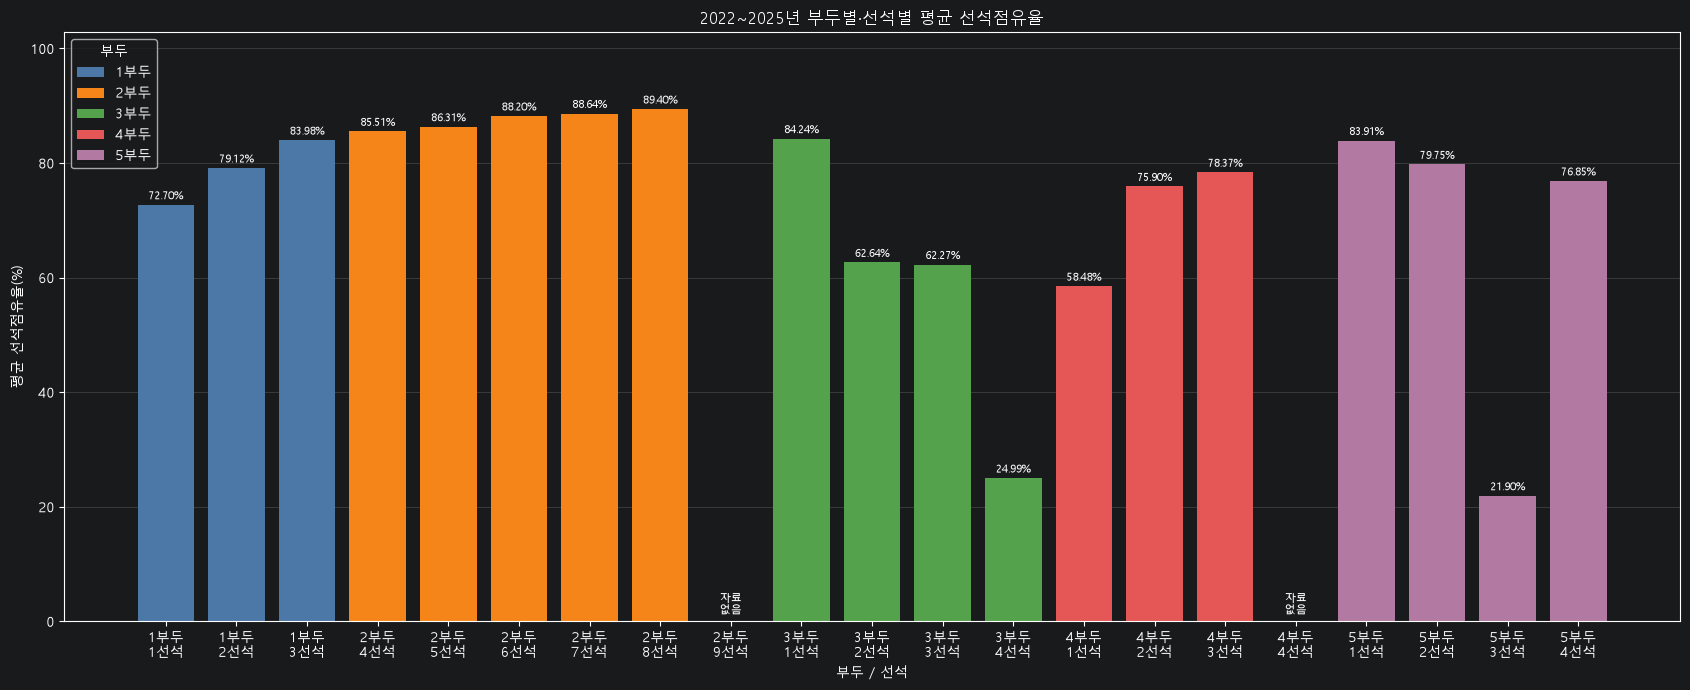

In [22]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# 1. 한글 설정
plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

# 2. CSV 불러오기
DATA_DIR = r"C:\work\Final_Project\data"

port1 = pd.read_csv(DATA_DIR + "/port1.csv", encoding="utf-8-sig")
port2 = pd.read_csv(DATA_DIR + "/port2.csv", encoding="cp949")
port3 = pd.read_csv(DATA_DIR + "/port3.csv", encoding="cp949")
port4 = pd.read_csv(DATA_DIR + "/port4.csv", encoding="cp949")
port5 = pd.read_csv(DATA_DIR + "/port5.csv", encoding="cp949")

ports = [
    (1, port1),
    (2, port2),
    (3, port3),
    (4, port4),
    (5, port5),
]

# 사진의 선석수와 CSV의 선석 번호 기준
expected_berths = {
    1: [1, 2, 3],
    2: [4, 5, 6, 7, 8, 9],
    3: [1, 2, 3, 4],
    4: [1, 2, 3, 4],
    5: [1, 2, 3, 4],
}

START = pd.Timestamp("2022-01-01")
END = pd.Timestamp("2026-01-01")
period_hours = (END - START).total_seconds() / 3600

# 3. 기간 내 작업시간 계산
frames = []

for number, port in ports:
    data = port.copy()

    data["접안시각"] = pd.to_datetime(
        data["접안(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    data["출항시각"] = pd.to_datetime(
        data["출항(예정)일시"],
        format="%Y-%m-%d %H:%M",
        errors="raise",
    )

    invalid = (
        data[["접안시각", "출항시각", "선석"]].isna().any(axis=1)
        | (data["출항시각"] < data["접안시각"])
    )

    if invalid.any():
        print(f"{number}부두: 오류·누락 {invalid.sum()}건 제외")

    data = data.loc[~invalid].copy()

    # 분석 기간과 겹치는 기록만 선택
    data = data.loc[
        (data["접안시각"] < END)
        & (data["출항시각"] > START)
    ].copy()

    # 2022~2025년에 해당하는 시간만 포함
    work_start = data["접안시각"].clip(lower=START)
    work_end = data["출항시각"].clip(upper=END)

    data["작업시간_시간"] = (
        work_end - work_start
    ).dt.total_seconds() / 3600

    data["부두"] = number

    frames.append(
        data[["부두", "선석", "작업시간_시간"]]
    )

detail = pd.concat(frames, ignore_index=True)

# 4. 부두별·선석별 총 작업시간
result = (
    detail.groupby(["부두", "선석"])
    .agg(총작업시간_시간=("작업시간_시간", "sum"))
)

# 기록이 없는 선석도 목록에 표시
expected_index = pd.MultiIndex.from_tuples(
    [
        (number, berth)
        for number, berths in expected_berths.items()
        for berth in berths
    ],
    names=["부두", "선석"],
)

result = result.reindex(expected_index).reset_index()

# 선석별 계산이므로 분모의 선석수는 1
result["평균선석점유율_퍼센트"] = (
    result["총작업시간_시간"] / period_hours * 100
)

print("\n2022~2025년 부두별·선석별 평균 선석점유율")
print(result.round(2).to_string(index=False, na_rep="자료 없음"))

# 5. 한 바그래프로 표시
labels = (
    result["부두"].astype(str) + "부두\n"
    + result["선석"].astype(str) + "선석"
)

port_colors = {
    1: "#4C78A8",
    2: "#F58518",
    3: "#54A24B",
    4: "#E45756",
    5: "#B279A2",
}

fig, ax = plt.subplots(figsize=(17, 7))

bars = ax.bar(
    labels,
    result["평균선석점유율_퍼센트"],
    color=result["부두"].map(port_colors),
)

for bar, value in zip(bars, result["평균선석점유율_퍼센트"]):
    if pd.isna(value):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            1,
            "자료\n없음",
            ha="center",
            va="bottom",
            fontsize=8,
        )
    else:
        ax.annotate(
            f"{value:.2f}%",
            xy=(bar.get_x() + bar.get_width() / 2, value),
            xytext=(0, 4),
            textcoords="offset points",
            ha="center",
            fontsize=8,
        )

ax.set_title("2022~2025년 부두별·선석별 평균 선석점유율")
ax.set_xlabel("부두 / 선석")
ax.set_ylabel("평균 선석점유율(%)")

maximum = result["평균선석점유율_퍼센트"].max()
upper = max(100, maximum * 1.15) if pd.notna(maximum) else 100
ax.set_ylim(0, upper)

ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.3)

ax.legend(
    handles=[
        Patch(facecolor=color, label=f"{number}부두")
        for number, color in port_colors.items()
    ],
    title="부두",
)

plt.tight_layout()
plt.show()